# Lecture 4 — QFT & Quantum Phase Estimation (UnitaryLab companion)

This notebook builds the quantum Fourier transform (QFT) and quantum phase
estimation (QPE) with the UnitaryLab simulator (v1.1.4). Run top to bottom.

Contents:
1. The $n$-qubit QFT circuit, verified against the DFT matrix
2. QPE with an *exact* eigenphase ($\varphi=1/4$), recovered exactly
3. QPE with a *non-exact* eigenphase, showing a peaked distribution (bar plot)

In [1]:
import numpy as np
from unitarylab.core import Circuit

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
%matplotlib inline

## 1. The QFT circuit

On $n$ qubits the QFT maps $|j\rangle \mapsto
\frac{1}{\sqrt{2^n}}\sum_k e^{2\pi i jk/2^n}|k\rangle$. The standard circuit
applies, for each qubit, a Hadamard followed by controlled-phase rotations
$R_m$ (phase $2\pi/2^m$) from the less-significant qubits, then reverses the
qubit order with swaps. We use `cp(angle, control, target)` (which applies
$e^{i\,\text{angle}}$ on $|11\rangle$) for the controlled phases — **not** `rx`.

With UnitaryLab's convention (qubit 0 = LSB), we treat qubit $n-1$ as the most
significant. We build the QFT and verify it against the explicit DFT matrix.

In [2]:
def qft(qc, qubits):
    '''Apply QFT on the given list of qubits (qubits[0] most significant).'''
    m = len(qubits)
    for i in range(m):
        qc.h(qubits[i])
        for j in range(i+1, m):
            angle = 2*np.pi / 2**(j - i + 1)
            qc.cp(angle, qubits[j], qubits[i])
    # reverse order
    for i in range(m//2):
        qc.swap(qubits[i], qubits[m-1-i])

def qft_matrix_from_circuit(n):
    '''Extract the QFT unitary column by column by feeding basis states.'''
    dim = 2**n
    M = np.zeros((dim, dim), dtype=complex)
    order = list(range(n-1, -1, -1))   # qubit n-1 = MSB
    for j in range(dim):
        vec = np.zeros(dim, dtype=complex); vec[j] = 1.0
        qc = Circuit(n)
        qc.initialize(vec, target=list(range(n)))
        qft(qc, order)
        state = qc.execute(backend='numpy', dtype=np.complex128).state.ravel()
        M[:, j] = state
    return M

n = 3
M = qft_matrix_from_circuit(n)
# Reference DFT matrix
dim = 2**n
jk = np.outer(np.arange(dim), np.arange(dim))
DFT = np.exp(2j*np.pi*jk/dim) / np.sqrt(dim)
err = np.max(np.abs(M - DFT))
print('max |QFT_circuit - DFT| =', round(err, 12))
assert err < 1e-10, 'Circuit QFT must equal the DFT matrix'
print('assert passed: QFT circuit matches the DFT matrix')

max |QFT_circuit - DFT| = 0.0
assert passed: QFT circuit matches the DFT matrix


## 2. The QFT reveals periodicity

The QFT is a frequency detector. If the amplitudes are **periodic with period $r\mid N$**
($a_{x+r}=a_x$), a one-line shift argument ($\hat a_k=\omega^{rk}\hat a_k$) forces the QFT
to be **supported only on the frequency comb** $\{\ell\,N/r\}$ — *regardless* of the
pattern within one period. Three regimes, demonstrated below:

1. **Single-spike comb** (one nonzero per period — the Shor period-finding state): the
   output is an *equal-height* comb at $\{\ell N/r\}$.
2. **General periodic** (several nonzeros per period): the output is *still* supported on
   $\{\ell N/r\}$, but the heights are *unequal* (they are the DFT of one period, and some
   comb points can even vanish). Periodicity fixes the comb **support**, not the heights.
3. **$r\nmid N$**: there is no exact comb — the output is only *peaked near* multiples of
   $N/r$, and $r$ is recovered from a measured value by **continued fractions** (Shor's
   order finding, §4.2 / Ch. 5).

In [3]:
# ---- helpers: build a period-r state, run it through the QFT, read probabilities ----
def comb_state(r, x0, n):
    '''Single nonzero per period: equal spikes on x0, x0+r, x0+2r, ... < N.'''
    N = 2**n; v = np.zeros(N, dtype=complex); m = 0
    while x0 + m*r < N:
        v[x0 + m*r] = 1.0; m += 1
    return v / np.linalg.norm(v)

def qft_probs(v, n):
    qc = Circuit(n)
    qc.initialize(v, target=list(range(n)))
    qft(qc, list(range(n-1, -1, -1)))                 # qubit n-1 = MSB (matches section 1)
    return np.abs(qc.execute(backend='numpy', dtype=np.complex128).state.ravel()) ** 2

def convergent_denominators(k, N):
    '''Denominators of the continued-fraction convergents of k/N (Shor post-processing).'''
    cf = []; a, b = k, N
    while b: cf.append(a // b); a, b = b, a % b
    p_prev, p, q_prev, q = 1, cf[0], 0, 1; dens = [q]
    for ai in cf[1:]:
        p_prev, p = p, ai*p + p_prev
        q_prev, q = q, ai*q + q_prev
        dens.append(q)
    return dens

# ---- (A) single-spike comb, r | N: output is an EQUAL-height comb at multiples of N/r ----
n = 3; N = 2**n
print("(A) single-spike comb (one nonzero per period), r | N:")
for r in [2, 4]:
    p = qft_probs(comb_state(r, 0, n), n)
    peaks = [k for k in range(N) if p[k] > 1e-9]
    spacing = peaks[1] - peaks[0]
    print(f"  r={r}: support {peaks} (spacing {spacing} = N/r), "
          f"heights {[round(p[k],3) for k in peaks]} (equal)  ->  r = N/spacing = {N//spacing}")
    assert N // spacing == r and np.allclose([p[k] for k in peaks], p[peaks[0]])

# ---- (B) general period-r amplitudes (two spikes/period), r | N:
#          SAME comb support {l N/r}, but UNEQUAL heights (some comb points can vanish) ----
print("\n(B) general period-r amplitudes (not single-spike), r | N:")
r = 4
amp = np.array([1, 1, 0, 0, 1, 1, 0, 0], dtype=complex)        # period 4, two nonzeros/period
p = qft_probs(amp / np.linalg.norm(amp), n)
peaks = [k for k in range(N) if p[k] > 1e-9]
print(f"  input amplitudes {amp.real.astype(int).tolist()} (period {r})")
print(f"  QFT support {peaks}  (all multiples of N/r = {N//r}),"
      f"  heights {[round(p[k],3) for k in peaks]} (UNEQUAL)")
assert all(k % (N // r) == 0 for k in peaks)                   # support lies on the comb
assert not np.allclose([p[k] for k in peaks], p[peaks[0]])     # but the heights differ
print("  -> periodicity fixes the comb SUPPORT; the within-period pattern sets the heights")

# ---- (C) r does NOT divide N (N=32, r=6): no exact comb; recover r by continued fractions ----
print("\n(C) r does NOT divide N  (N=32, r=6):")
n2 = 5; N2 = 2**n2; r = 6
p = qft_probs(comb_state(r, 0, n2), n2)
spread = int(np.sum(p > 1e-6))
top = sorted(range(N2), key=lambda k: -p[k])[:6]
print(f"  N/r = {N2/r:.3f} (not an integer); output spread over {spread} outcomes (no clean comb).")
all_dens = []
for k in sorted(top):
    dens = convergent_denominators(k, N2)
    all_dens += [d for d in dens if 1 < d < N2]
    print(f"    k={k:2d}  P={p[k]:.3f}   k/N = {k}/{N2}   convergent denominators {dens}")
print(f"  continued-fraction denominators from the peaks: {sorted(set(all_dens))}")
assert r in all_dens, "true period r=6 should appear among the continued-fraction denominators"
print(f"  -> r = {r} recovered (Shor combines several samples / takes the lcm of denominators)")

print("\nQFT period-finding verified across all three regimes (single-spike, general, r∤N).")

(A) single-spike comb (one nonzero per period), r | N:
  r=2: support [0, 4] (spacing 4 = N/r), heights [0.5, 0.5] (equal)  ->  r = N/spacing = 2
  r=4: support [0, 2, 4, 6] (spacing 2 = N/r), heights [0.25, 0.25, 0.25, 0.25] (equal)  ->  r = N/spacing = 4

(B) general period-r amplitudes (not single-spike), r | N:
  input amplitudes [1, 1, 0, 0, 1, 1, 0, 0] (period 4)
  QFT support [0, 2, 6]  (all multiples of N/r = 2),  heights [0.5, 0.25, 0.25] (UNEQUAL)
  -> periodicity fixes the comb SUPPORT; the within-period pattern sets the heights

(C) r does NOT divide N  (N=32, r=6):
  N/r = 5.333 (not an integer); output spread over 30 outcomes (no clean comb).
    k= 0  P=0.188   k/N = 0/32   convergent denominators [1]
    k= 5  P=0.117   k/N = 5/32   convergent denominators [1, 6, 13, 32]
    k=11  P=0.117   k/N = 11/32   convergent denominators [1, 2, 3, 32]
    k=16  P=0.188   k/N = 16/32   convergent denominators [1, 2]
    k=21  P=0.117   k/N = 21/32   convergent denominators [1, 1, 

## 3. QPE with an exact eigenphase

Phase estimation finds $\varphi$ where $U|\psi\rangle = e^{2\pi i\varphi}|\psi\rangle$.
We use the single-qubit phase gate $U = \mathrm{diag}(1, e^{2\pi i\varphi})$ acting
on eigenstate $|1\rangle$, so $U|1\rangle = e^{2\pi i\varphi}|1\rangle$.

With $t$ counting qubits and $\varphi = 1/4$, the binary fraction $0.01$ is exact,
so QPE returns $k=1$ (since $\varphi = k/2^t$ with $t\ge2$) with certainty.

The algorithm: Hadamard the counting register, apply controlled-$U^{2^r}$ for each
counting qubit $r$, apply the inverse QFT, then measure.

In [4]:
def qpe_distribution(varphi, t):
    '''Run QPE with t counting qubits on U=diag(1, e^{2 pi i varphi}), eigenstate |1>.
       Counting qubits are 0..t-1 (qubit 0 = LSB); system qubit is t.'''
    n = t + 1
    sys = t
    qc = Circuit(n, name='qpe')
    qc.x(sys)                                # prepare eigenstate |1>
    for r in range(t):
        qc.h(r)
    # controlled-U^{2^r}: U^{2^r}|1> = e^{2 pi i varphi 2^r}|1>. Implement as a
    # controlled phase on the system qubit conditioned on counting qubit r.
    for r in range(t):
        angle = 2*np.pi*varphi*(2**r)
        qc.cp(angle, r, sys)                 # phase e^{i angle} when both r and sys are 1
    # inverse QFT on the counting register (qubit t-1 = MSB)
    inv = Circuit(t, name='iqft')
    order = list(range(t-1, -1, -1))
    _qft_into(inv, order)
    inv = inv.dagger()
    qc.append(inv, target=list(range(t)))
    res = qc.execute(backend='numpy', dtype=np.complex128)
    return res.probabilities

def _qft_into(qc, qubits):
    m = len(qubits)
    for i in range(m):
        qc.h(qubits[i])
        for j in range(i+1, m):
            angle = 2*np.pi / 2**(j - i + 1)
            qc.cp(angle, qubits[j], qubits[i])
    for i in range(m//2):
        qc.swap(qubits[i], qubits[m-1-i])

t = 4
probs = qpe_distribution(0.25, t)
# Aggregate over the counting register (drop the system qubit = leftmost key char).
counting = {}
for k, p in probs.items():
    ck = k[1:]                    # keys read q_t q_{t-1}...q_0; system qubit t is leftmost
    counting[ck] = counting.get(ck, 0.0) + p
best = max(counting, key=counting.get)
k_int = int(best, 2)
phi_est = k_int / 2**t
print('most likely k =', k_int, ' -> phi_est =', phi_est, ' (exact 0.25)')
assert abs(phi_est - 0.25) < 1e-9 and counting[best] > 0.999
print('assert passed: exact phase 1/4 recovered with certainty')

most likely k = 4  -> phi_est = 0.25  (exact 0.25)
assert passed: exact phase 1/4 recovered with certainty


## 4. QPE with a non-exact eigenphase

For $\varphi = 0.3$ (not a dyadic fraction $k/2^t$), QPE returns a distribution
peaked at the nearest grid points $k/2^t$. We plot the distribution over the
counting register.

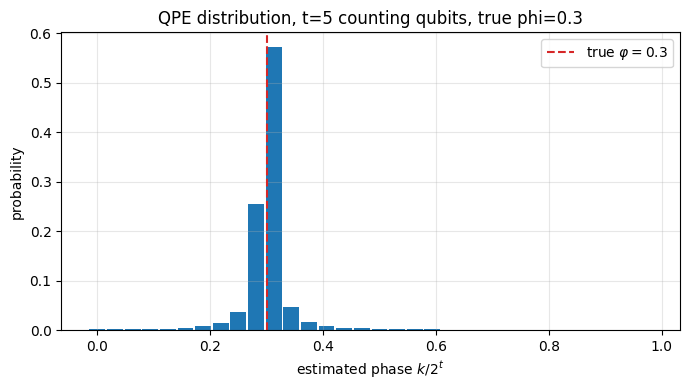

peak at phi = 0.3125  (nearest grid point to 0.3 )
assert passed: peak lies within one grid step of the true phase


In [5]:
t = 5
varphi = 0.3
probs = qpe_distribution(varphi, t)
counting = {}
for k, p in probs.items():
    ck = k[1:]
    counting[ck] = counting.get(ck, 0.0) + p
ks = np.arange(2**t)
pvals = np.array([counting.get(format(k, f'0{t}b'), 0.0) for k in ks])
phi_grid = ks / 2**t

plt.figure(figsize=(7,4))
plt.bar(phi_grid, pvals, width=1/2**t*0.9, color='C0')
plt.axvline(varphi, color='C3', ls='--', label=f'true $\\varphi={varphi}$')
plt.xlabel(r'estimated phase $k/2^t$'); plt.ylabel('probability')
plt.title(f'QPE distribution, t={t} counting qubits, true phi={varphi}')
plt.legend(); plt.grid(True, alpha=0.3); plt.tight_layout(); plt.show()

best = phi_grid[np.argmax(pvals)]
print('peak at phi =', round(best, 4), ' (nearest grid point to', varphi, ')')
assert abs(best - varphi) <= 1.0/2**t
print('assert passed: peak lies within one grid step of the true phase')

### Your turn
- Increase $t$ in the non-exact case and watch the peak sharpen around $0.3$.
- Try $\varphi = 3/8$ with $t=3$ (exact, $k=3$) and confirm certainty.
- Replace the controlled-phase shortcut with a genuine controlled-$U^{2^r}$ via
  `append(U, target=[sys], control=[r])` applied $2^r$ times, and check the
  distribution is unchanged.